<a href="https://colab.research.google.com/github/nahomephrem014/waste-classifier/blob/main/waste_classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

hello, I'm learning machine learning
120
100
['joseph', 'alexander', 'nahom', 'renee', 'sophia', 'charles', 'claire']
renee
7
['joseph', 'alexander', 'nahom', 'renee', 'sophia', 'charles', 'claire', 'emma yin']
nahom is the goat
['nahom', 'alex', 'joseph']
['nahom', 'alex', 'joseph']
['joseph', 'alexander', 'nahom', 'renee', 'sophia', 'charles', 'claire', 'emma yin', 'genius']
['nahom', 'alex', 'joseph', 'cardboard']
nahom -> trash
alex -> trash
joseph -> trash
cardboard -> recyclable
soda can -> recyclable
water bottle -> recyclable
pizza -> trash
recycling
pizza box -> I guess trash I'm 12 % sure.
cardboard -> I guess trash I'm 12 % sure.
water bottle -> I guess recycling I'm 12 % sure.
soda can -> I guess recycling I'm 12 % sure.
soda can -> I guess recycling I'm 12 % sure.
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
replace /content/extracted_data/DATASET/TEST/O/O_12568.jpg? [y]es, [n]o, [A]ll, [N]

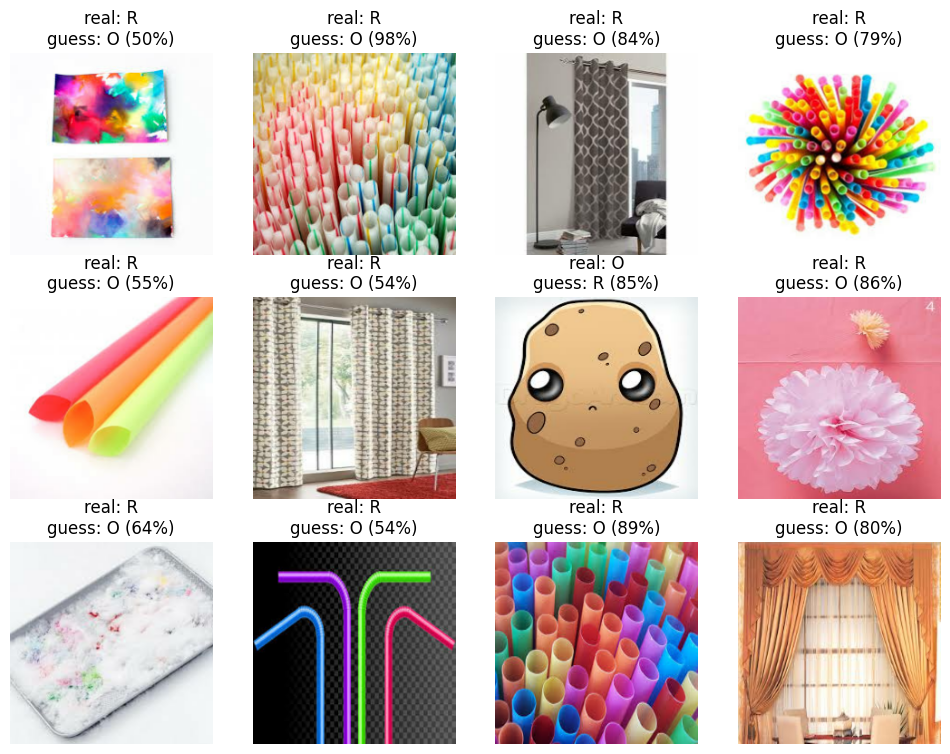

In [ ]:
from google.colab import drive
drive.mount ('/content/drive')

!unzip -q "/content/drive/MyDrive/waste classification data.zip" -d "/content/extracted_data"

import os

print(os.listdir("/content/extracted_data/DATASET"))
print(len(os.listdir("/content/extracted_data/DATASET/TRAIN/O")))
print(len(os.listdir("/content/extracted_data/DATASET/TRAIN/R")))

import tensorflow as tf

train_ds = tf.keras.utils.image_dataset_from_directory(
    "/content/extracted_data/DATASET/TRAIN", image_size=(224, 224), batch_size=32)

test_ds = tf.keras.utils.image_dataset_from_directory(
    "/content/extracted_data/DATASET/TEST", image_size=(224, 224), batch_size=32)

print(train_ds.class_names)


print (tf.config.list_physical_devices('GPU'))
base = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3), include_top=False, weights="imagenet")
base.trainable = False

model = tf.keras.Sequential([
    tf.keras.layers.Rescaling(1./127.5, offset=-1),
    base,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(2, activation="softmax")
])

model.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

# model.fit(train_ds, epochs=3)
model.evaluate(test_ds)
model.save("/content/drive/MyDrive/trash_model.keras")

import numpy as np
import matplotlib.pyplot as plt

class_names = train_ds.class_names
wrong_images = []
wrong_info = []

for images, labels in test_ds:
    probs = model.predict(images, verbose=0)
    guesses = np.argmax(probs, axis=1)
    for i in range(len(labels)):
        if guesses[i] != labels[i]:
            wrong_images.append(images[i].numpy().astype("uint8"))
            wrong_info.append((labels[i].numpy(), guesses[i], probs[i][guesses[i]]))

print(len(wrong_images), "wrong out of 2513")
o_called_r = sum(1 for real, guess, conf in wrong_info if real == 0)
r_called_o = sum(1 for real, guess, conf in wrong_info if real == 1)
print("Organic photos it called recyclable:", o_called_r)
print("Recyclable photos it called organic:", r_called_o)

plt.figure(figsize=(12, 9))
for i in range(min(12, len(wrong_images))):
    plt.subplot(3, 4, i + 1)
    plt.imshow(wrong_images[i])
    real, guess, conf = wrong_info[i]
    plt.title("real: " + class_names[real] + "\nguess: " + class_names[guess] + " (" + str(int(conf * 100)) + "%)")
    plt.axis("off")
plt.show()



In [ ]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomBrightness(0.2),
])

base2 = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3), include_top=False, weights="imagenet")
base2.trainable = False

model2 = tf.keras.Sequential([
    data_augmentation,
    tf.keras.layers.Rescaling(1./127.5, offset=-1),
    base2,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(2, activation="softmax")
])

model2.compile(optimizer="adam",
               loss="sparse_categorical_crossentropy",
               metrics=["accuracy"])

model2.fit(train_ds, epochs=3)
model2.evaluate(test_ds)
model2.save("/content/drive/MyDrive/trash_model_v2.keras")

Epoch 1/3
706/706 ━━━━━━━━━━━━━━━━━━━━ 125s 163ms/step - accuracy: 0.9165 - loss: 0.2145
Epoch 2/3
706/706 ━━━━━━━━━━━━━━━━━━━━ 124s 176ms/step - accuracy: 0.9342 - loss: 0.1747
Epoch 3/3
706/706 ━━━━━━━━━━━━━━━━━━━━ 109s 154ms/step - accuracy: 0.9378 - loss: 0.1644
79/79 ━━━━━━━━━━━━━━━━━━━━ 14s 149ms/step - accuracy: 0.8989 - loss: 0.2308


In [ ]:
print(train_ds.class_names, test_ds.class_names)
model.evaluate(train_ds.take(80))

import numpy as np

guesses = []
for images, labels in test_ds:
    guesses.extend(np.argmax(model.predict(images, verbose=0), axis=1))

print("guessed O:", guesses.count(0), " guessed R:", guesses.count(1))

['O', 'R'] ['O', 'R']
80/80 ━━━━━━━━━━━━━━━━━━━━ 10s 127ms/step - accuracy: 0.9570 - loss: 0.1135
guessed O: 1595  guessed R: 918


In [ ]:
import numpy as np

def count_mistakes(m):
    o_called_r = 0
    r_called_o = 0
    for images, labels in test_ds:
        guesses = np.argmax(m.predict(images, verbose=0), axis=1)
        for real, guess in zip(labels.numpy(), guesses):
            if real == 0 and guess == 1:
                o_called_r += 1
            if real == 1 and guess == 0:
                r_called_o += 1
    print("Organic called recyclable:", o_called_r)
    print("Recyclable called organic:", r_called_o)

count_mistakes(model2)

NameError: name 'model2' is not defined

In [ ]:
print("tf:", "tf" in globals())
print("train_ds:", "train_ds" in globals())
print("test_ds:", "test_ds" in globals())
print("model2:", "model2" in globals())

tf: True
train_ds: True
test_ds: True
model2: True


In [ ]:
model2.evaluate(test_ds)

79/79 ━━━━━━━━━━━━━━━━━━━━ 11s 134ms/step - accuracy: 0.8989 - loss: 0.2308


[0.2307552993297577, 0.8989256024360657]

In [ ]:
count_mistakes(model2)

Organic called recyclable: 40
Recyclable called organic: 214


In [ ]:
model3 = tf.keras.models.load_model("/content/drive/MyDrive/trash_model.keras")

base3 = [l for l in model3.layers if "mobilenet" in l.name][0]
base3.trainable = True
for layer in base3.layers[:-30]:
    layer.trainable = False
for layer in base3.layers[-30:]:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

model3.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
               loss="sparse_categorical_crossentropy",
               metrics=["accuracy"])

model3.fit(train_ds, epochs=3)
model3.evaluate(test_ds)
model3.save("/content/drive/MyDrive/trash_model_v3.keras")

Epoch 1/3
  7/706 ━━━━━━━━━━━━━━━━━━━━ 1:13 106ms/step - accuracy: 0.9555 - loss: 0.1160